# APS2 — Regressão do preço de anúncios Airbnb em Nova York

**Disciplina:** Machine Learning  
**Grupo:** Maria Eduarda Oliveira Galdino e Tomaz Santos Almeida  
**Dataset:** New York City Airbnb Open Data (`AB_NYC_2019.csv`)  
**Problema:** regressão — prever o preço anunciado por noite (`price`, em USD)  
**Prazo de entrega informado:** 30/10/2026  
**Data de elaboração:** 28/10/2026

Esta etapa reutiliza as decisões de pré-processamento da APS1. A seleção dos modelos e da transformação adicional usa somente treino e validação cruzada. O conjunto de teste reservado é avaliado depois da seleção final.

## 1. Objetivo e protocolo de avaliação

Compararemos um baseline Dummy, uma regressão linear regularizada e um ensemble de árvores. A métrica principal é o **MAE (erro absoluto médio), em dólares**: por exemplo, MAE de 50 significa erro absoluto médio de US$ 50 por anúncio.

A comparação e as buscas usam validação cruzada de cinco folds no conjunto de treino, com os mesmos folds para todos os modelos. O holdout de teste da APS1 fica fora da escolha de modelo e hiperparâmetros. Essa separação evita relatar como desempenho final uma métrica já otimizada durante a busca.

In [1]:
from pathlib import Path
import os
import sys
import warnings

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    raise FileNotFoundError("Abra este notebook na pasta raiz do repositório.")

os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".matplotlib"))
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    cross_val_score,
    learning_curve,
)

from nyc_airbnb_eda.modeling import (
    aggregate_encoded_importance,
    build_log_target_pipeline,
    build_model_pipeline,
    original_feature_name,
)
from nyc_airbnb_eda.preprocessing import split_data

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 12, "axes.labelsize": 10})

OUTPUT_DIR = PROJECT_ROOT / "reports" / "figures" / "aps2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "AB_NYC_2019.csv"
print("Python:", sys.version.split()[0])
print("scikit-learn:", __import__("sklearn").__version__)
print("SHAP:", shap.__version__)
print("CSV:", DATA_PATH)

Python: 3.11.9
scikit-learn: 1.8.0
SHAP: 0.51.0
CSV: C:\Users\tomaz\OneDrive\Documentos\Insper\4° sem\ML (Machine Learning)\APS\nyc-airbnb-eda-pipeline\data\raw\AB_NYC_2019.csv


## 2. Leitura e auditoria da base

Os 11 anúncios com `price = 0` são removidos conforme a decisão da APS1. Os 14 casos com `minimum_nights > 365` são mantidos; a APS1 os classificou como potencialmente inconsistentes, mas plausíveis para estadias longas. A coluna `host_id` é preservada somente para auditar a estrutura dos grupos: o pré-processador não a usa como preditora.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"CSV não encontrado em {DATA_PATH}. Coloque AB_NYC_2019.csv em data/raw/."
    )

df = pd.read_csv(DATA_PATH)
print(f"Base original: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
print("Colunas:", ", ".join(df.columns))
print("Preços não positivos:", int((df["price"] <= 0).sum()))
print("minimum_nights > 365:", int((df["minimum_nights"] > 365).sum()))
display(
    pd.DataFrame({
        "ausentes": df.isna().sum(),
        "%": (df.isna().mean() * 100).round(2),
    }).query("ausentes > 0").sort_values("ausentes", ascending=False)
)

Base original: 48,895 linhas × 16 colunas
Colunas: id, name, host_id, host_name, neighbourhood_group, neighbourhood, latitude, longitude, room_type, price, minimum_nights, number_of_reviews, last_review, reviews_per_month, calculated_host_listings_count, availability_365
Preços não positivos: 11
minimum_nights > 365: 14


,ausentes,%
reviews_per_month,10052,20.56
last_review,10052,20.56
host_name,21,0.04
name,16,0.03


## 3. Divisão treino/teste e risco de dependência por anfitrião

`split_data` remove o alvo inválido, separa 80%/20% com `random_state=42` e estratifica por decis de preço, reproduzindo a APS1. O teste não participa de validação cruzada, busca de hiperparâmetros ou decisão sobre a transformação do alvo.

Como um anfitrião pode ter vários anúncios, uma divisão aleatória por linha pode colocar anúncios do mesmo anfitrião nos dois lados. Calculamos a sobreposição para registrar essa limitação do desenho experimental.

In [3]:
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)
print(f"Treino: {X_train.shape[0]:,} anúncios; teste: {X_test.shape[0]:,} anúncios")
print(f"Mediana de price — treino/teste: ${y_train.median():.2f} / ${y_test.median():.2f}")

train_hosts = set(X_train["host_id"])
test_hosts = set(X_test["host_id"])
shared_hosts = train_hosts.intersection(test_hosts)
overlap_pct = 100 * len(shared_hosts) / max(len(test_hosts), 1)
print(
    f"Anfitriões únicos no teste: {len(test_hosts):,}; "
    f"também presentes no treino: {len(shared_hosts):,} ({overlap_pct:.1f}%)"
)

Treino: 39,107 anúncios; teste: 9,777 anúncios
Mediana de price — treino/teste: $106.00 / $106.00
Anfitriões únicos no teste: 8,727; também presentes no treino: 2,142 (24.5%)


## 4. Modelos, métrica e validação cruzada

Todos os estimadores recebem dados ainda não processados. O pré-processador da APS1 está dentro de cada `Pipeline`, então imputação, escala e categorias são aprendidas novamente dentro de cada fold.

- **Dummy:** prevê a mediana do preço do treino, referência simples e robusta à cauda longa.
- **Ridge:** modelo linear regularizado; ajustaremos `alpha`.
- **Random Forest:** ensemble de árvores; ajustaremos número de árvores, profundidade, tamanho mínimo de folha e fração de atributos.

As buscas são sequenciais (`n_jobs=1`) para limitar cópias de matrizes densas durante os folds.

In [4]:
CV = KFold(n_splits=5, shuffle=True, random_state=42)
SCORING = "neg_mean_absolute_error"
RIDGE_ALPHAS = np.logspace(-3, 3, 7)
RF_DISTRIBUTIONS = {
    "model__n_estimators": [80, 120],
    "model__max_depth": [None, 15, 25],
    "model__min_samples_leaf": [1, 3, 8],
    "model__max_features": [0.5, 0.75, 1.0],
}

def tune_estimator(name, log_target=False):
    # Use the same MAE and folds on raw price or log1p(price).
    if name == "Ridge":
        estimator = build_log_target_pipeline(Ridge()) if log_target else build_model_pipeline(Ridge())
        prefix = "regressor__model__" if log_target else "model__"
        return GridSearchCV(
            estimator,
            {f"{prefix}alpha": RIDGE_ALPHAS},
            scoring=SCORING,
            cv=CV,
            n_jobs=1,
            pre_dispatch=1,
            refit=True,
            return_train_score=True,
        )
    if name == "Random Forest":
        estimator = (
            build_log_target_pipeline(RandomForestRegressor(random_state=42, n_jobs=1))
            if log_target
            else build_model_pipeline(RandomForestRegressor(random_state=42, n_jobs=1))
        )
        prefix = "regressor__" if log_target else ""
        params = {f"{prefix}{key}": values for key, values in RF_DISTRIBUTIONS.items()}
        return RandomizedSearchCV(
            estimator,
            params,
            n_iter=6,
            scoring=SCORING,
            cv=CV,
            n_jobs=1,
            pre_dispatch=1,
            random_state=42,
            refit=True,
            return_train_score=True,
        )
    if name == "Dummy median":
        estimator = (
            build_log_target_pipeline(DummyRegressor())
            if log_target
            else build_model_pipeline(DummyRegressor(strategy="median"))
        )
        if not log_target:
            return estimator
        return GridSearchCV(
            estimator,
            {"regressor__model__strategy": ["mean", "median"]},
            scoring=SCORING,
            cv=CV,
            n_jobs=1,
            pre_dispatch=1,
            refit=True,
            return_train_score=True,
        )
    raise ValueError(f"Modelo não reconhecido: {name}")

### 4.1 Baseline Dummy

O Dummy também passa pelo pré-processador para manter a avaliação reproduzível dentro do mesmo fluxo. Seu resultado de validação cruzada será a referência para os modelos treinados.

In [5]:
dummy_pipeline = build_model_pipeline(DummyRegressor(strategy="median"))
dummy_scores = cross_val_score(
    dummy_pipeline,
    X_train,
    y_train,
    scoring=SCORING,
    cv=CV,
    n_jobs=1,
)
dummy_mae_mean = -dummy_scores.mean()
dummy_mae_std = dummy_scores.std(ddof=1)
print(f"Dummy median — MAE CV: ${dummy_mae_mean:.2f} ± ${dummy_mae_std:.2f}")

Dummy median — MAE CV: $83.66 ± $1.36


### 4.2 Ridge: busca de regularização

A busca seleciona `alpha` pela média do MAE nos mesmos cinco folds. A escala é o preço original em dólares.

In [6]:
ridge_search = tune_estimator("Ridge")
ridge_search.fit(X_train, y_train)
print("Melhor alpha:", ridge_search.best_params_["model__alpha"])
print(f"Ridge — melhor MAE CV: ${-ridge_search.best_score_:.2f}")

Melhor alpha: 100.0
Ridge — melhor MAE CV: $70.78


### 4.3 Random Forest: busca do ensemble

`RandomizedSearchCV` amostra seis combinações da grade compacta. A configuração escolhida usa o mesmo MAE e os mesmos folds do Ridge. A floresta roda em um único processo para evitar paralelismo aninhado e pressão desnecessária de memória.

In [7]:
forest_search = tune_estimator("Random Forest")
forest_search.fit(X_train, y_train)
print("Melhores hiperparâmetros:")
display(pd.Series(forest_search.best_params_, name="valor").to_frame())
print(f"Random Forest — melhor MAE CV: ${-forest_search.best_score_:.2f}")

Melhores hiperparâmetros:
Random Forest — melhor MAE CV: $63.74


,valor
model__n_estimators,120.0
model__min_samples_leaf,8.0
model__max_features,0.5
model__max_depth,NaN


### 4.4 Comparação inicial

A tabela usa MAE positivo, em dólares. O desvio-padrão descreve a variação do score entre folds; a escolha é feita somente com validação cruzada.

,modelo,MAE médio CV (USD),desvio CV (USD)
0,Random Forest,$63.74,$1.71
1,Ridge,$70.78,$1.33
2,Dummy median,$83.66,$1.36


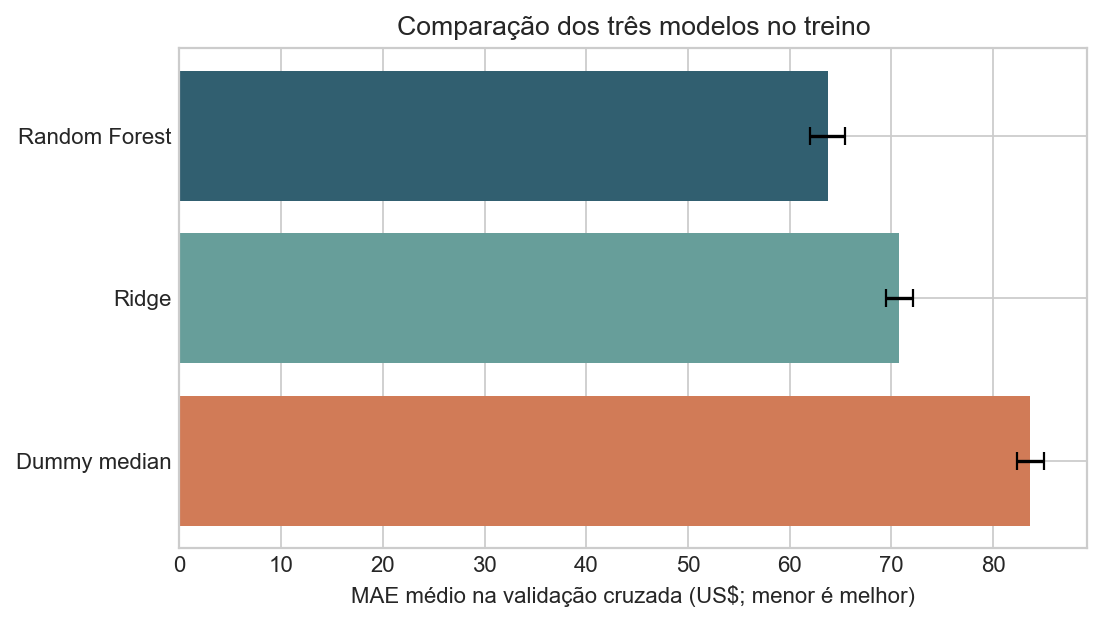

In [8]:
baseline_results = pd.DataFrame([
    {"modelo": "Dummy median", "MAE médio CV (USD)": dummy_mae_mean, "desvio CV (USD)": dummy_mae_std},
    {
        "modelo": "Ridge",
        "MAE médio CV (USD)": -ridge_search.best_score_,
        "desvio CV (USD)": ridge_search.cv_results_["std_test_score"][ridge_search.best_index_],
    },
    {
        "modelo": "Random Forest",
        "MAE médio CV (USD)": -forest_search.best_score_,
        "desvio CV (USD)": forest_search.cv_results_["std_test_score"][forest_search.best_index_],
    },
]).sort_values("MAE médio CV (USD)").reset_index(drop=True)
display(baseline_results.style.format({"MAE médio CV (USD)": "${:,.2f}", "desvio CV (USD)": "${:,.2f}"}))

plt.figure(figsize=(7, 4))
plt.barh(
    baseline_results["modelo"],
    baseline_results["MAE médio CV (USD)"],
    xerr=baseline_results["desvio CV (USD)"],
    color=["#315f70", "#679e9a", "#d17b57"],
    capsize=4,
)
plt.gca().invert_yaxis()
plt.xlabel("MAE médio na validação cruzada (US$; menor é melhor)")
plt.title("Comparação dos três modelos no treino")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "aps2_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Mudança no pipeline: transformar `price` com `log1p`

A APS1 observou cauda longa no preço e sugeriu testar `log1p(price)` na modelagem. A transformação é aplicada ao alvo dentro de `TransformedTargetRegressor`; `predict` retorna novamente dólares, inclusive durante a validação cruzada. Predições negativas após a inversão são limitadas a zero, pois um preço negativo não é válido.

Retunamos o modelo que teve menor MAE CV na comparação inicial. O impacto é calculado pela diferença entre os dois MAEs CV na escala original, usando a mesma estratégia de cinco folds. O holdout não decide essa escolha.

In [9]:
baseline_mae_by_name = {
    "Dummy median": dummy_mae_mean,
    "Ridge": -ridge_search.best_score_,
    "Random Forest": -forest_search.best_score_,
}
baseline_best_name = min(baseline_mae_by_name, key=baseline_mae_by_name.get)
baseline_best_mae = baseline_mae_by_name[baseline_best_name]
print(f"Melhor resultado inicial: {baseline_best_name} — ${baseline_best_mae:.2f} MAE CV")

target_search = tune_estimator(baseline_best_name, log_target=True)
target_search.fit(X_train, y_train)
target_mae = -target_search.best_score_
delta_mae = target_mae - baseline_best_mae
delta_pct = 100 * delta_mae / baseline_best_mae
print(f"Após log1p(price), MAE CV: ${target_mae:.2f}")
print(f"Diferença (transformado − original): ${delta_mae:+.2f} ({delta_pct:+.2f}%)")
print("Melhores hiperparâmetros após retuning:")
display(pd.Series(target_search.best_params_, name="valor").to_frame())

Melhor resultado inicial: Random Forest — $63.74 MAE CV
Após log1p(price), MAE CV: $56.12
Diferença (transformado − original): $-7.62 (-11.95%)
Melhores hiperparâmetros após retuning:


,valor
regressor__model__n_estimators,120.0
regressor__model__min_samples_leaf,1.0
regressor__model__max_features,0.5
regressor__model__max_depth,15.0


### 5.1 Escolha do modelo final

Comparamos a melhor versão original com a versão retunada após `log1p(price)`. A escolha final é feita por MAE CV, sem consultar o teste. Se a transformação não reduzir o erro, a versão original permanece como final.

In [10]:
baseline_estimators = {
    "Dummy median": dummy_pipeline.fit(X_train, y_train),
    "Ridge": ridge_search.best_estimator_,
    "Random Forest": forest_search.best_estimator_,
}
if target_mae < baseline_best_mae:
    final_model = target_search.best_estimator_
    final_model_name = f"{baseline_best_name} + log1p(price)"
    final_cv_mae = target_mae
    target_transformed = True
else:
    final_model = baseline_estimators[baseline_best_name]
    final_model_name = baseline_best_name
    final_cv_mae = baseline_best_mae
    target_transformed = False

print("Modelo selecionado pelo treino/CV:", final_model_name)
print(f"MAE CV usado na seleção: ${final_cv_mae:.2f}")
print("Target transformado:", target_transformed)

Modelo selecionado pelo treino/CV: Random Forest + log1p(price)
MAE CV usado na seleção: $56.12
Target transformado: True


## 6. Curva de aprendizado

Mantemos os hiperparâmetros escolhidos e variamos o tamanho do treino. A curva ajuda a avaliar o hiato entre treino e validação e se o erro de validação ainda melhora com mais exemplos. Ela usa apenas os dados de treino e o mesmo MAE.

,anúncios no treino,MAE treino (USD),MAE validação médio (USD),desvio validação (USD)
0,6257,$33.77,$58.46,$2.14
1,12514,$38.29,$57.37,$1.87
2,18771,$40.42,$56.83,$2.02
3,25028,$41.69,$56.47,$1.98
4,31285,$42.64,$56.14,$1.97


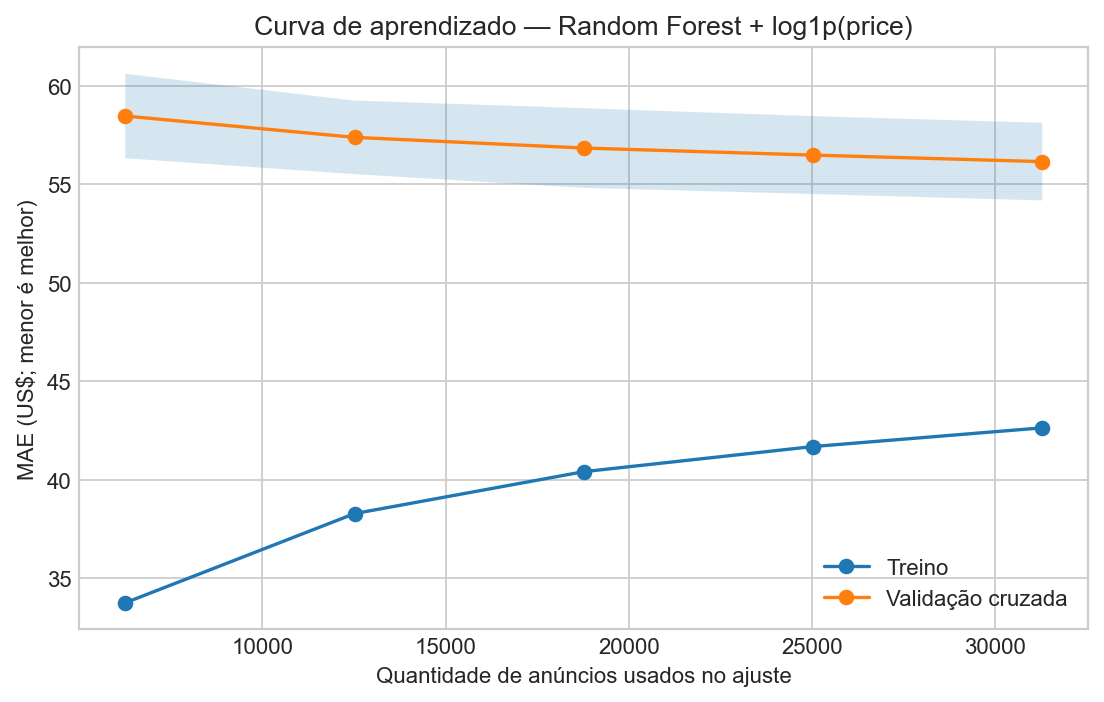

In [11]:
train_sizes, train_scores, validation_scores = learning_curve(
    final_model,
    X_train,
    y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=CV,
    scoring=SCORING,
    n_jobs=1,
    shuffle=True,
    random_state=42,
)
train_mae = -train_scores.mean(axis=1)
validation_mae = -validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1, ddof=1)

plt.figure(figsize=(7, 4.5))
plt.plot(train_sizes, train_mae, marker="o", label="Treino")
plt.plot(train_sizes, validation_mae, marker="o", label="Validação cruzada")
plt.fill_between(
    train_sizes,
    validation_mae - validation_std,
    validation_mae + validation_std,
    alpha=0.18,
)
plt.xlabel("Quantidade de anúncios usados no ajuste")
plt.ylabel("MAE (US$; menor é melhor)")
plt.title(f"Curva de aprendizado — {final_model_name}")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "aps2_learning_curve.png", dpi=160, bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "anúncios no treino": train_sizes,
    "MAE treino (USD)": train_mae,
    "MAE validação médio (USD)": validation_mae,
    "desvio validação (USD)": validation_std,
}).style.format({
    "MAE treino (USD)": "${:,.2f}",
    "MAE validação médio (USD)": "${:,.2f}",
    "desvio validação (USD)": "${:,.2f}",
}))

## 7. Avaliação final no conjunto de teste

O modelo final foi escolhido sem consultar o teste. Agora reportamos o MAE uma única vez no holdout e analisamos os três gráficos exigidos. Os resíduos são definidos como `real − previsto`: resíduos positivos indicam subestimação.

Modelo final: Random Forest + log1p(price)
MAE final no teste: $57.78
Número de anúncios no teste: 9,777


,price_real,price_previsto,residuo_real_menos_previsto
34851,3750,2254.285182,1495.714818
20783,190,363.926458,-173.926458
43933,160,205.084687,-45.084687
38447,139,144.615090,-5.615090
8687,69,65.937068,3.062932


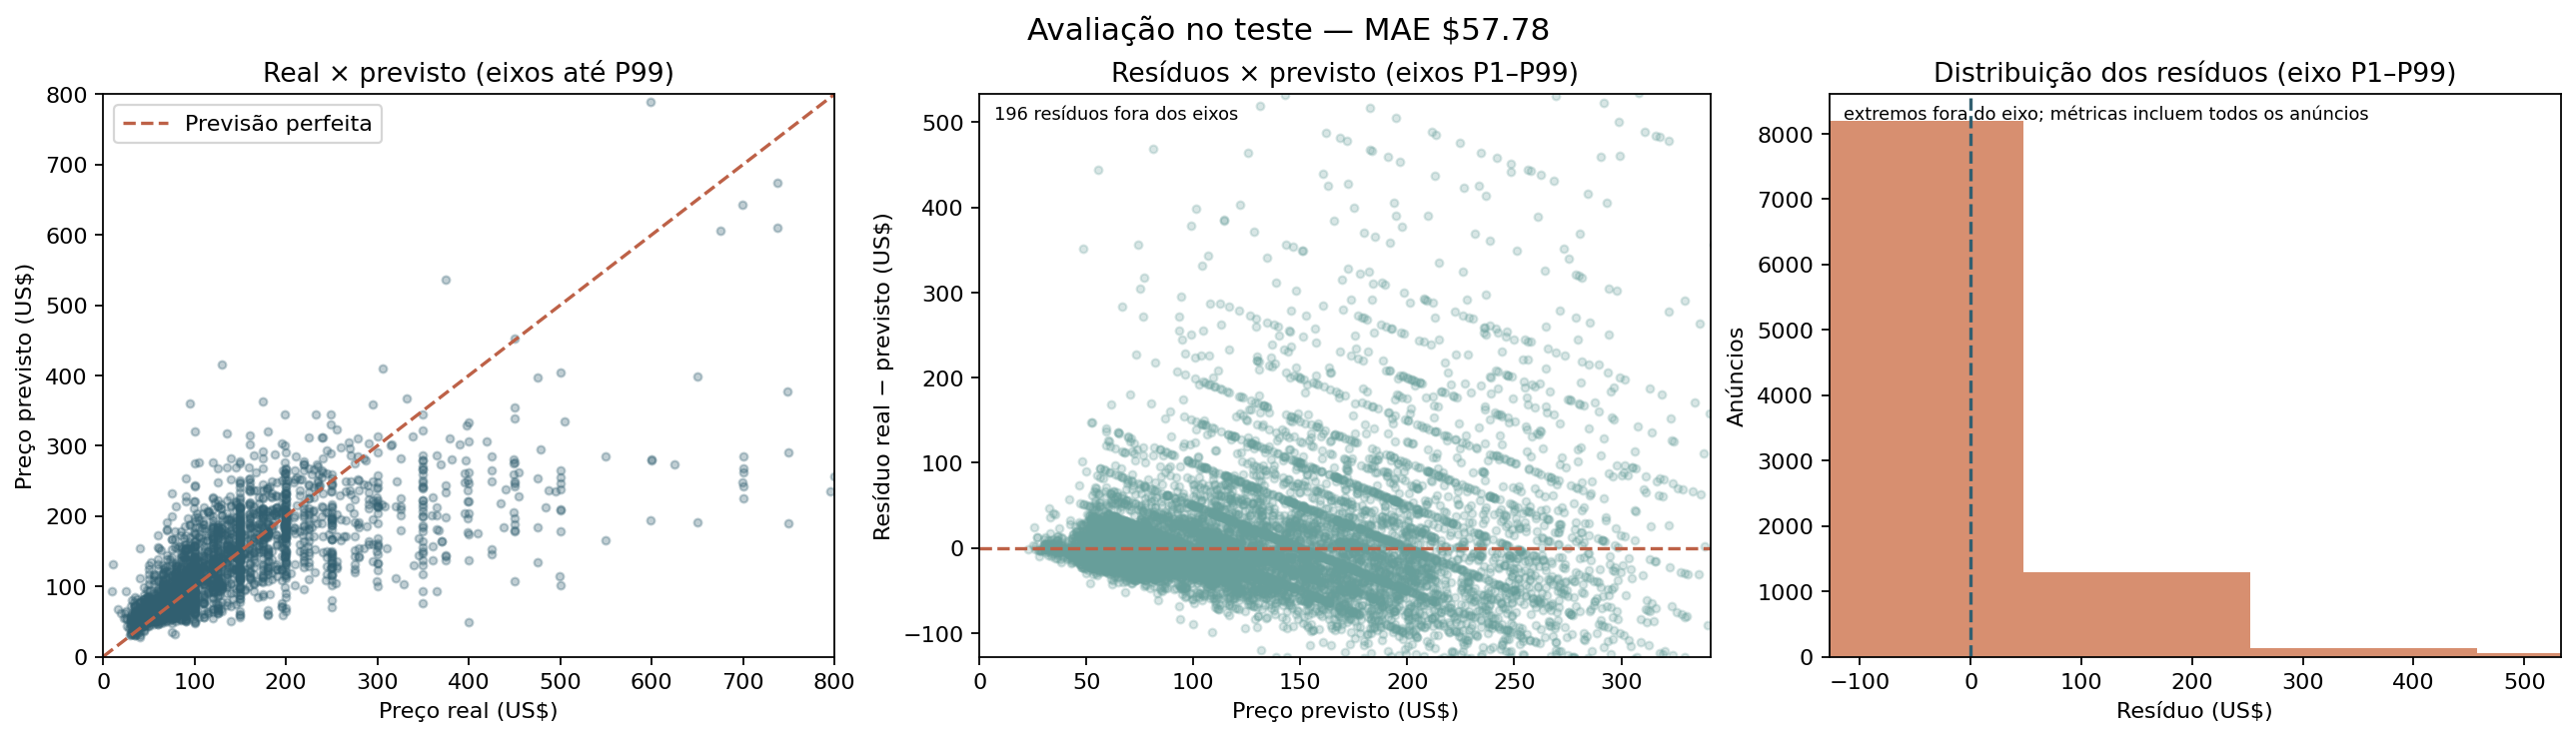

In [12]:
y_pred = final_model.predict(X_test)
test_mae = mean_absolute_error(y_test, y_pred)
residuals = y_test.to_numpy() - y_pred
print("Modelo final:", final_model_name)
print(f"MAE final no teste: ${test_mae:.2f}")
print(f"Número de anúncios no teste: {len(y_test):,}")

test_results = pd.DataFrame({
    "price_real": y_test.to_numpy(),
    "price_previsto": y_pred,
    "residuo_real_menos_previsto": residuals,
}, index=y_test.index)
display(test_results.head())

rng = np.random.default_rng(42)
sample_positions = rng.choice(len(y_test), size=min(2500, len(y_test)), replace=False)
real_sample = y_test.to_numpy()[sample_positions]
pred_sample = y_pred[sample_positions]
p99 = float(np.quantile(y_test, 0.99))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
axes[0].scatter(real_sample, pred_sample, alpha=0.3, s=12, color="#315f70")
axes[0].plot([0, p99], [0, p99], "--", color="#bd6147", label="Previsão perfeita")
axes[0].set(xlim=(0, p99), ylim=(0, p99), xlabel="Preço real (US$)", ylabel="Preço previsto (US$)", title="Real × previsto (eixos até P99)")
axes[0].legend()

axes[1].scatter(y_pred, residuals, alpha=0.25, s=12, color="#679e9a")
axes[1].axhline(0, linestyle="--", color="#bd6147")
residual_xmax = float(np.quantile(y_pred, 0.99))
residual_ymin, residual_ymax = np.quantile(residuals, [0.01, 0.99])
residuals_outside = int(((residuals < residual_ymin) | (residuals > residual_ymax)).sum())
axes[1].set(xlim=(0, residual_xmax), ylim=(residual_ymin, residual_ymax), xlabel="Preço previsto (US$)", ylabel="Resíduo real − previsto (US$)", title="Resíduos × previsto (eixos P1–P99)")
axes[1].text(0.02, 0.98, f"{residuals_outside} resíduos fora dos eixos", transform=axes[1].transAxes, va="top", fontsize=8)

axes[2].hist(residuals, bins=50, color="#d17b57", alpha=0.85)
axes[2].axvline(0, linestyle="--", color="#315f70")
hist_xmin, hist_xmax = np.quantile(residuals, [0.01, 0.99])
axes[2].set_xlim(hist_xmin, hist_xmax)
axes[2].set(xlabel="Resíduo (US$)", ylabel="Anúncios", title="Distribuição dos resíduos (eixo P1–P99)")
axes[2].text(0.02, 0.98, "extremos fora do eixo; métricas incluem todos os anúncios", transform=axes[2].transAxes, va="top", fontsize=8)
fig.suptitle(f"Avaliação no teste — MAE ${test_mae:,.2f}", fontsize=14)
fig.savefig(OUTPUT_DIR / "aps2_test_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

### 7.1 Erro por faixa de preço

O MAE agregado pode esconder diferenças entre anúncios baratos e caros. Esta tabela descreve o erro por decis do preço real no teste; ela serve para a discussão crítica e não será usada para retunar o modelo.

In [13]:
test_error_by_decile = pd.DataFrame({
    "price_real": y_test.to_numpy(),
    "price_previsto": y_pred,
    "erro_absoluto": np.abs(y_test.to_numpy() - y_pred),
})
test_error_by_decile["decil_preco"] = pd.qcut(
    test_error_by_decile["price_real"], q=10, labels=False, duplicates="drop"
) + 1
mae_by_price_decile = test_error_by_decile.groupby("decil_preco").agg(
    anuncios=("erro_absoluto", "size"),
    mediana_preco_real=("price_real", "median"),
    mae_usd=("erro_absoluto", "mean"),
    erro_assinado_usd=("price_real", lambda values: float(np.mean(
        values.to_numpy() - test_error_by_decile.loc[values.index, "price_previsto"].to_numpy()
    ))),
)
display(mae_by_price_decile.style.format({
    "mediana_preco_real": "${:,.2f}", "mae_usd": "${:,.2f}", "erro_assinado_usd": "${:+,.2f}"
}))

,anuncios,mediana_preco_real,mae_usd,erro_assinado_usd
decil_preco,,,,
1,1003,$40.00,$18.58,$-18.12
2,1007,$55.00,$15.35,$-13.38
3,1037,$70.00,$18.63,$-10.25
4,930,$85.00,$25.24,$-11.24
5,915,$100.00,$32.85,$-19.79
6,1046,$120.00,$34.53,$-15.26
7,910,$149.00,$38.72,$-12.27
8,987,$175.00,$39.98,$-0.68
9,966,$225.00,$51.06,$+30.11


## 8. Interpretação dos modelos

O Ridge fornece direção e magnitude dos coeficientes condicionais às demais colunas. As variáveis numéricas foram padronizadas, enquanto as categorias one-hot são binárias; portanto, a escala das comparações deve ser explicada. As importâncias da floresta são relativas e não indicam causalidade. Também agrupamos as colunas one-hot por variável original para não dividir a leitura entre dezenas de bairros.

Três coeficientes Ridge de maior magnitude (com sinal):
Três maiores importâncias individuais da Random Forest:
Importância agregada por variável original:


,feature_codificada,feature_original,coeficiente
122,categorical__neighbourhood_Tribeca,neighbourhood,+167.179
136,categorical__room_type_Entire home/apt,room_type,+78.130
9,categorical__neighbourhood_group_Manhattan,neighbourhood_group,+60.568


,feature_codificada,feature_original,importancia
5,numeric__longitude,longitude,0.1781
4,numeric__latitude,latitude,0.1400
6,numeric__availability_365,availability_365,0.1320


,feature_original,importancia
9,room_type,0.1919
3,longitude,0.1781
2,latitude,0.1400
0,availability_365,0.1320
4,minimum_nights,0.1094
5,neighbourhood,0.0645
1,calculated_host_listings_count,0.0596
8,reviews_per_month,0.0555
7,number_of_reviews,0.0454
6,neighbourhood_group,0.0237


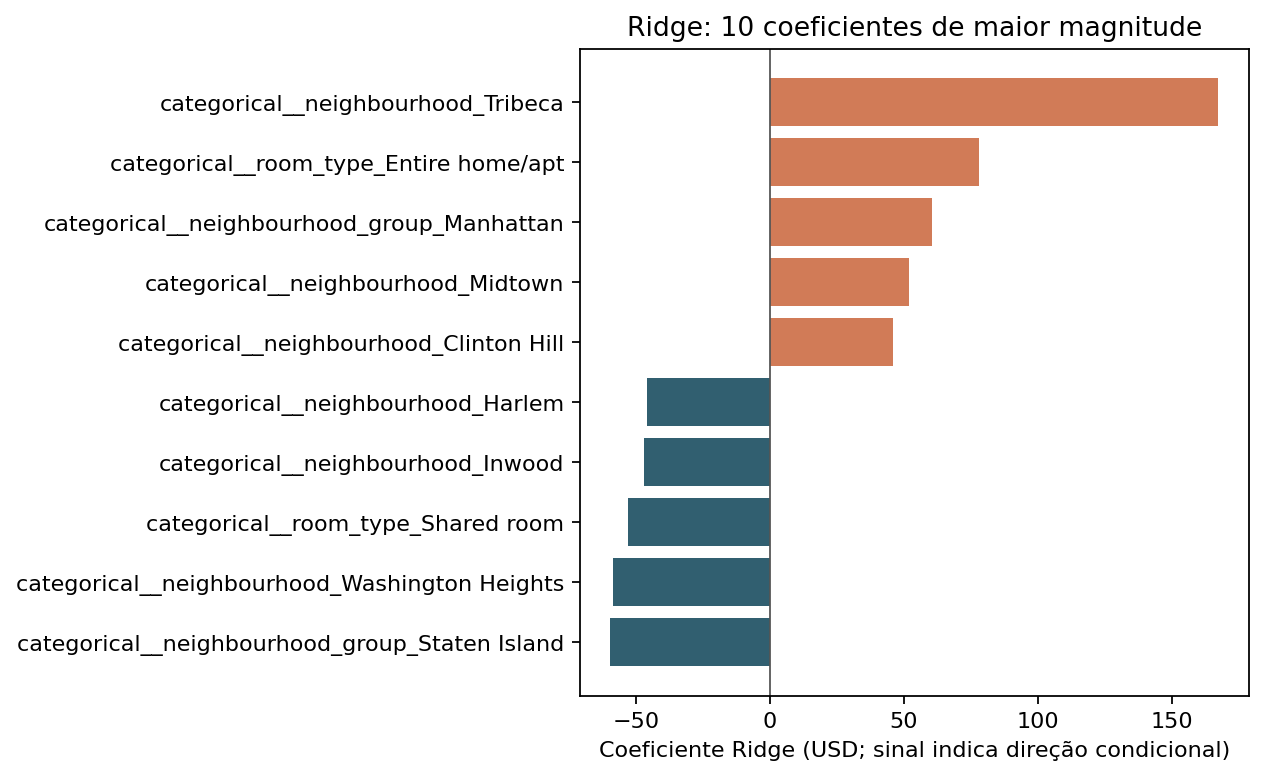

In [14]:
feature_names = get_preprocessed_feature_names(ridge_search.best_estimator_.named_steps["preprocessor"])
ridge_values = ridge_search.best_estimator_.named_steps["model"].coef_
ridge_features = pd.DataFrame({
    "feature_codificada": feature_names,
    "feature_original": [original_feature_name(name) for name in feature_names],
    "coeficiente": ridge_values,
})
ridge_top3 = ridge_features.reindex(ridge_features["coeficiente"].abs().sort_values(ascending=False).index).head(3)
print("Três coeficientes Ridge de maior magnitude (com sinal):")
display(ridge_top3.style.format({"coeficiente": "{:+,.3f}"}))

ridge_top10 = ridge_features.assign(magnitude=ridge_features["coeficiente"].abs()).nlargest(10, "magnitude").sort_values("coeficiente")
ridge_colors = ["#d17b57" if value > 0 else "#315f70" for value in ridge_top10["coeficiente"]]
plt.figure(figsize=(8, 5))
plt.barh(ridge_top10["feature_codificada"], ridge_top10["coeficiente"], color=ridge_colors)
plt.axvline(0, color="#555555", linewidth=0.8)
plt.xlabel("Coeficiente Ridge (USD; sinal indica direção condicional)")
plt.title("Ridge: 10 coeficientes de maior magnitude")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "aps2_ridge_coefficients.png", dpi=160, bbox_inches="tight")
plt.show()

forest_feature_names = get_preprocessed_feature_names(forest_search.best_estimator_.named_steps["preprocessor"])
forest_values = forest_search.best_estimator_.named_steps["model"].feature_importances_
forest_features = pd.DataFrame({
    "feature_codificada": forest_feature_names,
    "feature_original": [original_feature_name(name) for name in forest_feature_names],
    "importancia": forest_values,
}).sort_values("importancia", ascending=False)
print("Três maiores importâncias individuais da Random Forest:")
display(forest_features.head(3).style.format({"importancia": "{:.4f}"}))

forest_grouped = forest_features.groupby("feature_original", as_index=False)["importancia"].sum().sort_values(
    "importancia", ascending=False
)
print("Importância agregada por variável original:")
display(forest_grouped.head(10).style.format({"importancia": "{:.4f}"}))
plt.figure(figsize=(7, 4.5))
top_forest = forest_grouped.head(10).sort_values("importancia")
plt.barh(top_forest["feature_original"], top_forest["importancia"], color="#d17b57")
plt.xlabel("Importância relativa agregada")
plt.title("Random Forest: importância por variável original")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "aps2_forest_importance.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Explicabilidade com SHAP

A importância global é a média de `|SHAP|` numa amostra fixa de treino. Para três previsões no teste, escolhemos um caso de subestimação, um de superestimação e um com erro absoluto próximo da mediana. As explicações são calculadas depois da seleção e avaliação final; não serão usadas para modificar o modelo.

Se o modelo final foi treinado com `log1p(price)`, SHAP explica a saída interna na escala `log1p(price)`. A predição reportada ao lado de cada caso continua na escala original em dólares. As atribuições são associativas ao modelo e não representam efeitos causais.

In [15]:
if target_transformed:
    fitted_pipeline = final_model.regressor_
    explanation_scale = "log1p(price)"
else:
    fitted_pipeline = final_model
    explanation_scale = "price (USD)"

final_preprocessor = fitted_pipeline.named_steps["preprocessor"]
final_estimator = fitted_pipeline.named_steps["model"]
final_feature_names = get_preprocessed_feature_names(final_preprocessor)
global_raw = X_train.sample(n=min(400, len(X_train)), random_state=42)
global_transformed = final_preprocessor.transform(global_raw)

if isinstance(final_estimator, RandomForestRegressor):
    shap_explainer = shap.TreeExplainer(
        final_estimator,
        feature_perturbation="tree_path_dependent",
        feature_names=final_feature_names,
    )
    global_shap = shap_explainer(global_transformed)
elif isinstance(final_estimator, Ridge):
    shap_explainer = shap.LinearExplainer(
        final_estimator,
        global_transformed[: min(100, len(global_transformed))],
        feature_perturbation="interventional",
        feature_names=final_feature_names,
    )
    global_shap = shap_explainer(global_transformed)
else:
    # Um Dummy é constante: SHAP atribui contribuição zero a cada atributo.
    shap_explainer = shap.Explainer(
        final_estimator.predict,
        global_transformed[:20],
        algorithm="permutation",
        feature_names=final_feature_names,
        seed=42,
    )
    global_shap = shap_explainer(
        global_transformed[: min(20, len(global_transformed))],
        max_evals=2 * len(final_feature_names) + 1,
    )

print(f"Escala da explicação: {explanation_scale}")
mean_abs_shap = np.abs(global_shap.values).mean(axis=0)
shap_by_encoded_feature = pd.Series(mean_abs_shap, index=final_feature_names)
shap_by_original_feature = pd.Series({
    original_feature_name(name): float(values.sum())
    for name, values in shap_by_encoded_feature.groupby(
        [original_feature_name(name) for name in shap_by_encoded_feature.index]
    )
}).sort_values(ascending=False)
display(shap_by_original_feature.head(12).rename("média de |SHAP| agregada"))

top_shap = shap_by_original_feature.head(12).sort_values()
plt.figure(figsize=(7, 5))
plt.barh(top_shap.index, top_shap.values, color="#315f70")
plt.xlabel(f"Média de |SHAP| ({explanation_scale}; one-hot agregado)")
plt.title("Importância global SHAP por variável original")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "aps2_shap_global.png", dpi=160, bbox_inches="tight")
plt.show()

Escala da explicação: log1p(price)


,média de |SHAP| agregada
room_type,0.391609
longitude,0.147351
availability_365,0.104450
neighbourhood_group,0.074610
latitude,0.068393
minimum_nights,0.055613
neighbourhood,0.045965
number_of_reviews,0.027880
reviews_per_month,0.026720
calculated_host_listings_count,0.013242


In [16]:
signed_residuals = y_test.to_numpy() - y_pred
absolute_residuals = np.abs(signed_residuals)
local_positions = [
    int(np.argmax(signed_residuals)),
    int(np.argmin(signed_residuals)),
    int(np.argmin(np.abs(absolute_residuals - np.median(absolute_residuals)))),
]
local_positions = list(dict.fromkeys(local_positions))
for position in range(len(local_positions), 3):
    local_positions.append(position)
local_positions = local_positions[:3]
local_raw = X_test.iloc[local_positions]
local_transformed = final_preprocessor.transform(local_raw)
local_shap = shap_explainer(local_transformed)

case_labels = ["maior subestimação", "maior superestimação", "erro absoluto mediano"]
local_summary = []
for label, position, shap_row in zip(case_labels, local_positions, local_shap, strict=False):
    local_summary.append({
        "caso": label,
        "preço real (USD)": float(y_test.iloc[position]),
        "preço previsto (USD)": float(y_pred[position]),
        "resíduo real − previsto (USD)": float(signed_residuals[position]),
    })
display(pd.DataFrame(local_summary).style.format({
    "preço real (USD)": "${:,.2f}",
    "preço previsto (USD)": "${:,.2f}",
    "resíduo real − previsto (USD)": "${:+,.2f}",
}))

for index, (label, shap_row) in enumerate(zip(case_labels, local_shap, strict=False), start=1):
    plt.figure(figsize=(9, 5))
    shap.plots.waterfall(shap_row, max_display=10, show=False)
    plt.title(f"Caso {index}: {label} — explicação em {explanation_scale}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"aps2_shap_case_{index}.png", dpi=160, bbox_inches="tight")
    plt.show()

,caso,preço real (USD),preço previsto (USD),resíduo real − previsto (USD)
0,maior subestimação,"$9,999.00",$116.18,"$+9,882.82"
1,maior superestimação,$180.00,$542.49,$-362.49
2,erro absoluto mediano,$62.00,$85.38,$-23.38


## 10. Discussão crítica

### Limitações do modelo

1. **Erro não uniforme na cauda:** o MAE geral do teste foi US$ 57,78, mas no decil de anúncios mais caros chegou a US$ 305,11; o resíduo médio real − previsto foi +US$ 301,59. O exemplo mais extremo foi um anúncio de US$ 9.999 previsto em aproximadamente US$ 116. A transformação do alvo reduziu o erro médio, mas não resolveu a subestimação dos anúncios mais caros.
2. **Extrapolação limitada:** a Random Forest constrói previsões a partir das respostas observadas nas folhas e não extrapola uma tendência de preço para além da faixa aprendida. Isso limita o uso em anúncios premium ou em um mercado futuro com valores acima dos dados de treinamento.

### Limitações dos dados ainda não discutidas na APS1

1. **Dependência entre linhas do mesmo anfitrião:** 24,5% dos anfitriões únicos no teste também aparecem no treino. Anúncios do mesmo anfitrião podem compartilhar características, então um split aleatório por linha pode superestimar a generalização para anfitriões novos. Uma análise complementar deve separar por `host_id` com `GroupKFold`.
2. **Cobertura da amostra:** a base reúne anúncios do Airbnb em Nova York; ela não representa automaticamente toda a oferta de hospedagem, aluguel ou imóveis fora da plataforma e da cidade. As conclusões ficam restritas a esse universo observado.

### Ações para operacionalização e manutenção

1. **Empacotar e versionar:** registrar versão do modelo e do pré-processamento, esquema esperado, snapshot dos dados, hiperparâmetros e versões de Python/bibliotecas junto ao artefato. Isso permite reproduzir a validação e reconstruir o modelo.
2. **Monitorar e revisar:** acompanhar qualidade/ausências das entradas, distribuição de preço, MAE quando preços observados estiverem disponíveis e erros por segmento — especialmente a cauda de preços altos. Definir revisão/re-treinamento quando as métricas saírem dos limites acordados ou a distribuição mudar.

Para um trabalho futuro, uma validação `GroupKFold` por anfitrião pode medir generalização para grupos não vistos. Ela é apresentada como sensibilidade; não substitui a divisão exigida e comparável com a APS1.


## 11. Conclusões

O modelo final foi a Random Forest treinada com `log1p(price)`. A busca reduziu o MAE de validação cruzada de US$ 63,74 para US$ 56,12 (−11,95%); no teste reservado, o MAE foi US$ 57,78. O desempenho no teste ficou próximo da validação, mas a tabela por decis mostra que o erro cresce muito nos anúncios mais caros.

Na curva de aprendizado, o MAE de validação caiu de US$ 58,46 para US$ 56,14 à medida que aumentou o treino; a curva ainda melhora, mas com ganho menor nos tamanhos finais. O MAE de treino subiu de US$ 33,77 para US$ 42,64, mantendo um hiato de aproximadamente US$ 13,50 para a validação no maior tamanho.

A análise de importância da floresta destacou `room_type`, longitude, latitude e disponibilidade. No SHAP global, `room_type`, longitude e `availability_365` tiveram as maiores atribuições agregadas. Essas medidas explicam associações usadas pelo modelo e não efeitos causais. As explicações SHAP do modelo final estão na escala `log1p(price)`.


In [17]:
summary = pd.Series({
    "modelo final": final_model_name,
    "MAE validação cruzada (USD)": final_cv_mae,
    "MAE teste (USD)": test_mae,
    "MAE baseline Dummy (USD)": dummy_mae_mean,
    "MAE inicial do melhor modelo (USD)": baseline_best_mae,
    "MAE após log1p(price) e retuning (USD)": target_mae,
}, name="resultado")
display(summary)

,resultado
modelo final,Random Forest + log1p(price)
MAE validação cruzada (USD),56.12
MAE teste (USD),57.777416
MAE baseline Dummy (USD),83.659432
MAE inicial do melhor modelo (USD),63.739068
MAE após log1p(price) e retuning (USD),56.12


## Referências

- Kaggle. *New York City Airbnb Open Data*. https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR, 12, 2825–2830.
- Scikit-learn. *Pipeline and composite estimators*. https://scikit-learn.org/stable/modules/compose.html
- Scikit-learn. *GridSearchCV*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- Scikit-learn. *Mean absolute error*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html
- Scikit-learn. *Learning curves*. https://scikit-learn.org/stable/modules/learning_curve.html
- Scikit-learn. *Model persistence*. https://scikit-learn.org/stable/model_persistence.html
- Lundberg, S. M., & Lee, S. I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS. https://papers.nips.cc/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html
- SHAP. *TreeExplainer*. https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html
- NIST. *AI Risk Management Framework Playbook — Manage*. https://airc.nist.gov/airmf-resources/playbook/manage/